In [1]:
!pip install pennylane

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 84.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 48.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 65.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 85.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 99.8 MB/s eta 0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1


--- [KOD 6] KLASİK K-MEANS VE KUANTUM KÜMELEME (5-FOLD CV) ---
Toplam Kümeleme Örneklemi: 300 (Fraud: 150, Normal: 150)

PCA İlk 4 Bileşenin Varyans Oranları: [0.3859 0.1215 0.0903 0.0611]
Toplam Açıklanan Varyans: %65.88

Tüm Kümeleme Kümesi için Kuantum Mesafe Matrisi (300x300) Hesaplanıyor...
   -> Kuantum Mesafe Matrisi: 50/300 satır tamamlandı (44.5 sn).
   -> Kuantum Mesafe Matrisi: 100/300 satır tamamlandı (81.0 sn).
   -> Kuantum Mesafe Matrisi: 150/300 satır tamamlandı (109.5 sn).
   -> Kuantum Mesafe Matrisi: 200/300 satır tamamlandı (130.0 sn).
   -> Kuantum Mesafe Matrisi: 250/300 satır tamamlandı (142.2 sn).
   -> Kuantum Mesafe Matrisi: 300/300 satır tamamlandı (145.9 sn).

--- 5-Fold Çapraz Doğrulama Döngüsü Başlatılıyor ---
Fold 1/5 -> Klasik F1: %53.66 | Kuantum F1: %63.64 | ARI: 0.208
Fold 2/5 -> Klasik F1: %57.14 | Kuantum F1: %60.47 | ARI: 0.178
Fold 3/5 -> Klasik F1: %33.33 | Kuantum F1: %66.67 | ARI: 0.240
Fold 4/5 -> Klasik F1: %53.66 | Kuantum F1: %60.47 | ARI: 

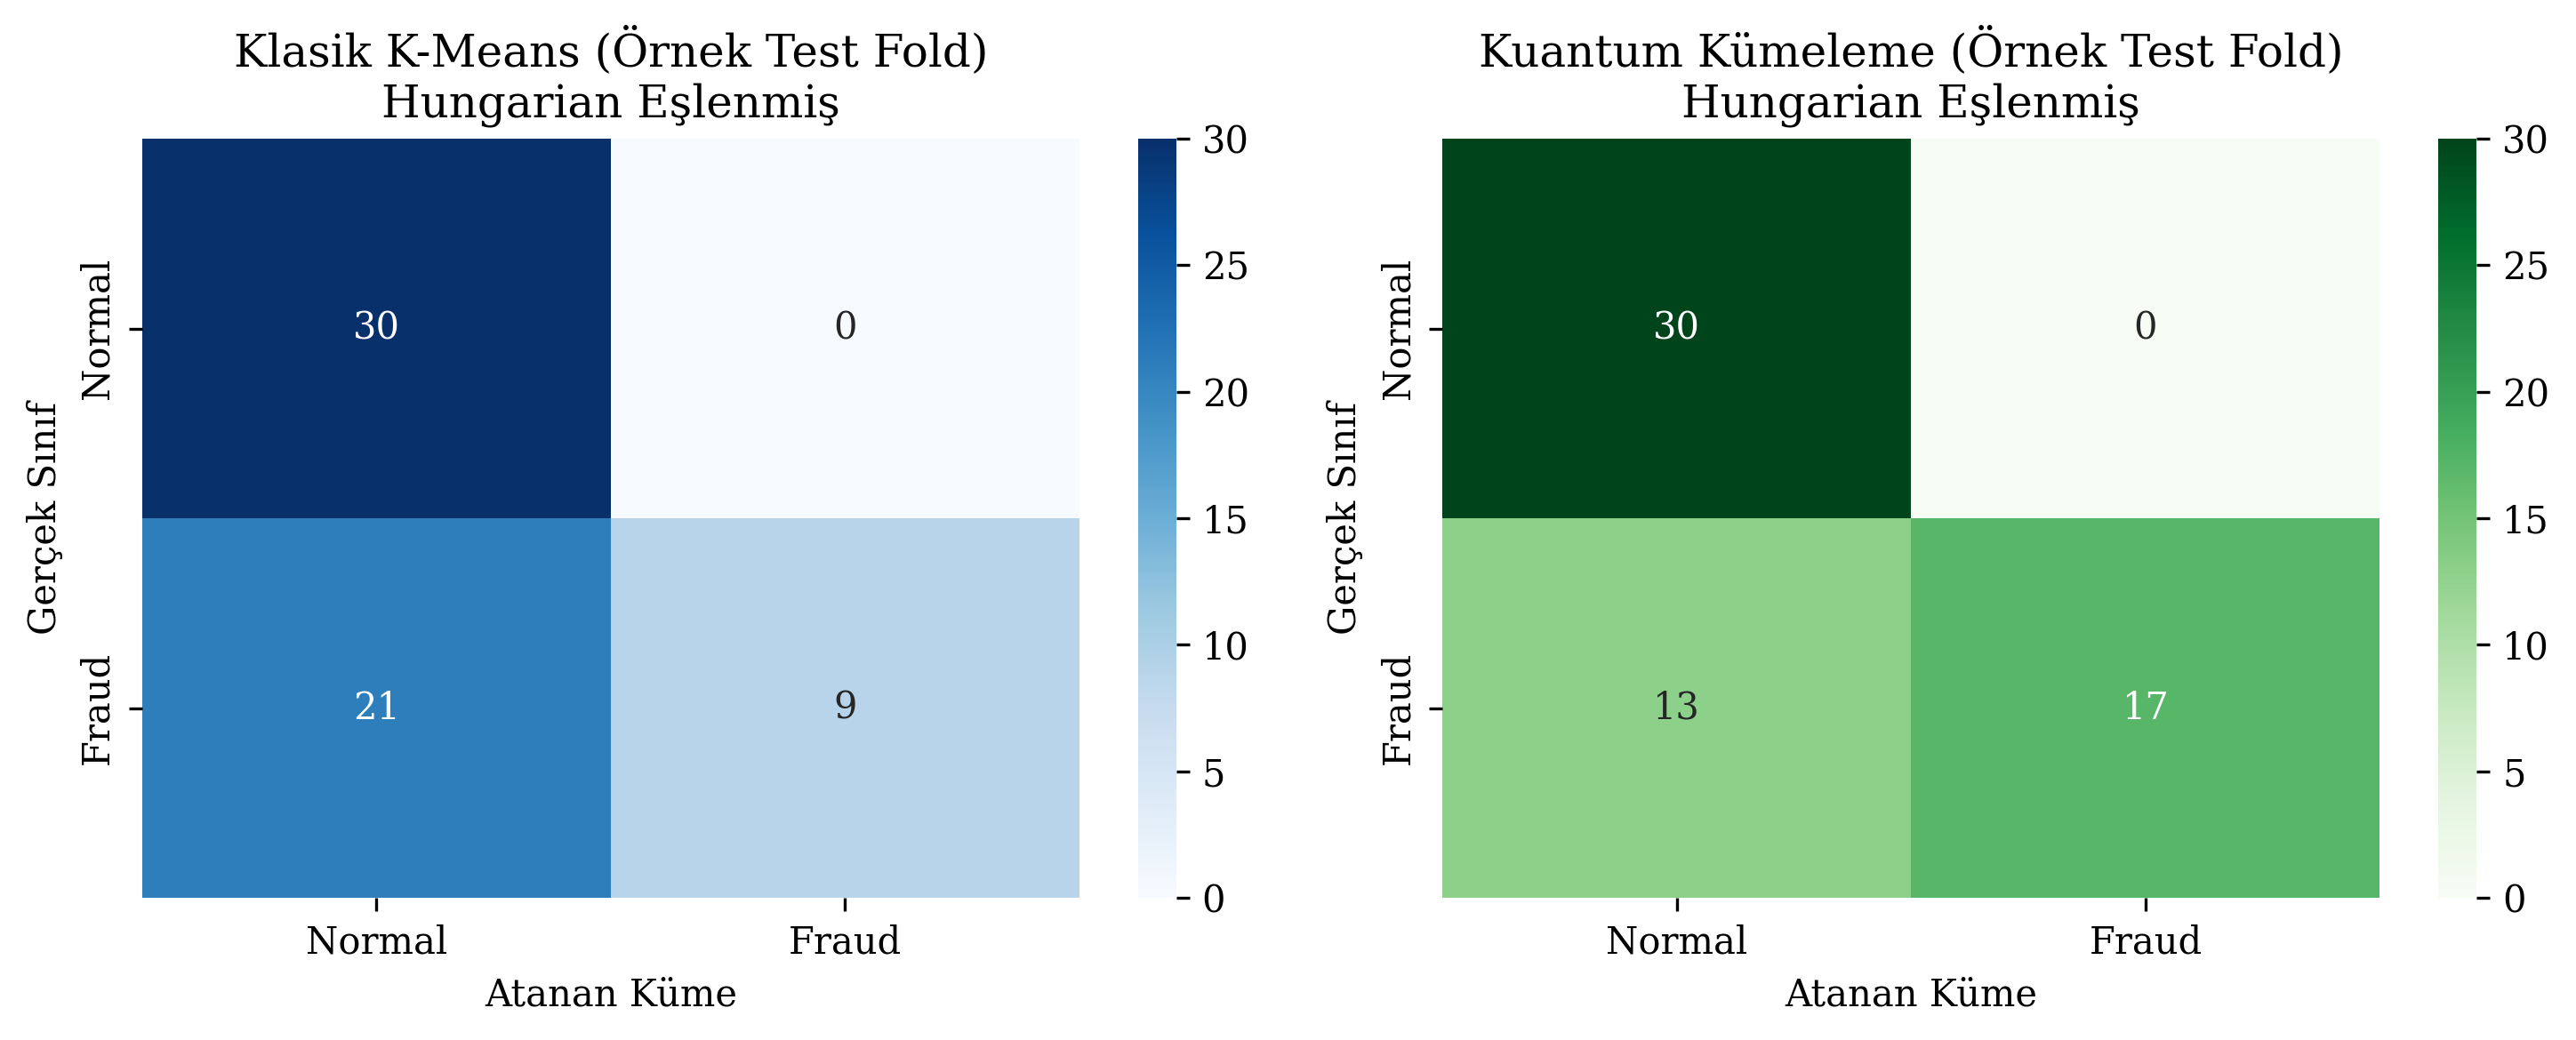

In [2]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml
import seaborn as sns
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    confusion_matrix,
    f1_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# ==========================================================
# 1. VERİ HAZIRLIĞI VE ÖRNEKLEME (HAKEM #2 YORUM #2)
# ==========================================================
print("--- [KOD 6] KLASİK K-MEANS VE KUANTUM KÜMELEME (5-FOLD CV) ---")
df = pd.read_csv("creditcard.csv")

RANDOM_SEED = 42
n_samples_per_class = 150  # 150 Normal + 150 Fraud = 300 Örnek

fraud = df[df["Class"] == 1].sample(n=n_samples_per_class, random_state=RANDOM_SEED)
normal = df[df["Class"] == 0].sample(n=n_samples_per_class, random_state=RANDOM_SEED)
df_balanced = (
    pd.concat([fraud, normal])
    .sample(frac=1, random_state=RANDOM_SEED)
    .reset_index(drop=True)
)

cols_to_drop = [col for col in ["Time", "Class"] if col in df_balanced.columns]
X_raw = df_balanced.drop(columns=cols_to_drop).values
y_raw = df_balanced["Class"].values

print(f"Toplam Kümeleme Örneklemi: {len(X_raw)} (Fraud: {np.sum(y_raw == 1)}, Normal: {np.sum(y_raw == 0)})\n")

# ==========================================================
# 2. HUNGARIAN ALGORİTMASI VE DEĞERLENDİRME (HAKEM #2 YORUM #13)
# ==========================================================
def align_and_evaluate(y_true_fold, cluster_preds, X_fold):
    """Kuhn-Munkres (Hungarian) algoritması ile optimal etiket eşleşmesi ve metrik hesabı."""
    cm = confusion_matrix(y_true_fold, cluster_preds)
    cost_matrix = np.max(cm) - cm
    row_ind, col_ind = linear_sum_assignment(cost_matrix)
    mapping = {col: row for row, col in zip(row_ind, col_ind)}
    y_aligned = np.array([mapping.get(c, c) for c in cluster_preds])

    acc = accuracy_score(y_true_fold, y_aligned)
    f1_b = f1_score(y_true_fold, y_aligned, pos_label=1, zero_division=0)
    f1_m = f1_score(y_true_fold, y_aligned, average="macro", zero_division=0)
    ari = adjusted_rand_score(y_true_fold, y_aligned)
    nmi = normalized_mutual_info_score(y_true_fold, y_aligned)
    sil = silhouette_score(X_fold, cluster_preds) if len(np.unique(cluster_preds)) > 1 else 0.0

    return {
        "acc": acc, "f1_bin": f1_b, "f1_macro": f1_m,
        "ari": ari, "nmi": nmi, "sil": sil, "y_aligned": y_aligned
    }

# ==========================================================
# 3. 4 KÜBİTLİK KUANTUM DEVRESİ VE ÇEKİRDEK HESAPLAMA
# ==========================================================
n_qubits = 4
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="autograd")
def overlap_qnode(x1, x2):
    qml.AngleEmbedding(x1, wires=range(n_qubits))
    qml.adjoint(qml.AngleEmbedding)(x2, wires=range(n_qubits))
    return qml.probs(wires=range(n_qubits))

def compute_quantum_distance_matrix(X):
    n = len(X)
    D = np.zeros((n, n))
    start_t = time.time()
    for i in range(n):
        for j in range(i, n):
            if i == j:
                D[i, j] = 0.0
            else:
                fidelity = overlap_qnode(X[i], X[j])[0]
                fidelity = np.clip(fidelity, 0.0, 1.0)
                # Bures / Fubini-Study Kuantum Durum Mesafesi: D = sqrt(2 - 2F)
                dist = np.sqrt(np.maximum(0.0, 2.0 - 2.0 * fidelity))
                D[i, j] = dist
                D[j, i] = dist
        if (i + 1) % 50 == 0 or i == n - 1:
            print(f"   -> Kuantum Mesafe Matrisi: {i+1}/{n} satır tamamlandı ({time.time() - start_t:.1f} sn).")
    return D

# 5-Fold için global kuantum mesafe matrisi
scaler_all = StandardScaler()
pca_all = PCA(n_components=n_qubits, random_state=RANDOM_SEED)
minmax_all = MinMaxScaler(feature_range=(-np.pi, np.pi))
X_all_angles = minmax_all.fit_transform(pca_all.fit_transform(scaler_all.fit_transform(X_raw)))

print(f"PCA İlk 4 Bileşenin Varyans Oranları: {np.round(pca_all.explained_variance_ratio_, 4)}")
print(f"Toplam Açıklanan Varyans: %{np.sum(pca_all.explained_variance_ratio_)*100:.2f}\n")

print("Tüm Kümeleme Kümesi için Kuantum Mesafe Matrisi (300x300) Hesaplanıyor...")
D_all_quantum = compute_quantum_distance_matrix(X_all_angles)

# ==========================================================
# 4. 5-FOLD STRATIFIED CROSS-VALIDATION DÖNGÜSÜ
# ==========================================================
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

classic_fold_results = {"acc": [], "f1_bin": [], "f1_macro": [], "ari": [], "nmi": [], "sil": []}
quantum_fold_results = {"acc": [], "f1_bin": [], "f1_macro": [], "ari": [], "nmi": [], "sil": []}

last_fold_y_test = None
last_fold_pred_cl = None
last_fold_pred_q = None

print("\n--- 5-Fold Çapraz Doğrulama Döngüsü Başlatılıyor ---")
for fold, (train_idx, test_idx) in enumerate(skf.split(X_raw, y_raw), 1):
    # A) SIZINTISIZ ÖN İŞLEME (KLASİK K-MEANS)
    X_tr_raw, X_te_raw = X_raw[train_idx], X_raw[test_idx]
    y_tr, y_te = y_raw[train_idx], y_raw[test_idx]

    scaler_f = StandardScaler()
    pca_f = PCA(n_components=n_qubits, random_state=RANDOM_SEED)
    minmax_f = MinMaxScaler(feature_range=(-np.pi, np.pi))

    X_tr_4d = minmax_f.fit_transform(pca_f.fit_transform(scaler_f.fit_transform(X_tr_raw)))
    X_te_4d = minmax_f.transform(pca_f.transform(scaler_f.transform(X_te_raw)))

    # Klasik K-Means: Train fold'da fit, Test fold'da predict
    km = KMeans(n_clusters=2, random_state=RANDOM_SEED, n_init=10)
    km.fit(X_tr_4d)
    preds_cl_te = km.predict(X_te_4d)

    res_cl = align_and_evaluate(y_te, preds_cl_te, X_te_4d)
    for k in classic_fold_results:
        classic_fold_results[k].append(res_cl[k])

    # B) KUANTUM KÜMELEME (TEST FOLD ATAMASI)
    # Eğitim katmanındaki kuantum medoid'leri (temsilci merkezleri) belirlenir
    tr_dist_sub = D_all_quantum[np.ix_(train_idx, train_idx)]
    km_q = KMeans(n_clusters=2, random_state=RANDOM_SEED, n_init=10).fit(tr_dist_sub)
    medoid_indices = [train_idx[np.argmin(np.linalg.norm(tr_dist_sub - c, axis=1))] for c in km_q.cluster_centers_]

    # Test örnekleri en yakın kuantum merkezine atanır
    test_dists = D_all_quantum[np.ix_(test_idx, medoid_indices)]
    preds_q_te = np.argmin(test_dists, axis=1)

    res_q = align_and_evaluate(y_te, preds_q_te, X_all_angles[test_idx])
    for k in quantum_fold_results:
        quantum_fold_results[k].append(res_q[k])

    print(f"Fold {fold}/5 -> Klasik F1: %{res_cl['f1_bin']*100:.2f} | Kuantum F1: %{res_q['f1_bin']*100:.2f} | ARI: {res_q['ari']:.3f}")

    if fold == 5:
        last_fold_y_test = y_te
        last_fold_pred_cl = res_cl["y_aligned"]
        last_fold_pred_q = res_q["y_aligned"]

# ==========================================================
# 5. HAKEM #2 YORUM #4 VE #13 İÇİN TABLO RAPORU
# ==========================================================
print("\n" + "=" * 95)
print("HAKEM RAPORU: 5-FOLD STRATIFIED CV KÜMELEME SONUÇLARI (Mean ± SD)")
print("=" * 95)
print(f"{'Metrik':<22} | {'Klasik K-Means (5-Fold CV)':<32} | {'Kuantum Kümeleme (5-Fold CV)'}")
print("-" * 95)

metric_defs = [
    ("Doğruluk (Acc)", "acc", True),
    ("F1-Skoru (Binary)", "f1_bin", True),
    ("F1-Skoru (Macro)", "f1_macro", True),
    ("Silüet Skoru", "sil", False),
    ("ARI Skoru", "ari", False),
    ("NMI Skoru", "nmi", False),
]

for label, key, is_pct in metric_defs:
    cl_m, cl_s = np.mean(classic_fold_results[key]), np.std(classic_fold_results[key])
    q_m, q_s = np.mean(quantum_fold_results[key]), np.std(quantum_fold_results[key])

    if is_pct:
        cl_str = f"%{cl_m*100:.2f} ± {cl_s*100:.2f}"
        q_str = f"%{q_m*100:.2f} ± {q_s*100:.2f}"
    else:
        cl_str = f"{cl_m:.3f} ± {cl_s:.3f}"
        q_str = f"{q_m:.3f} ± {q_s:.3f}"

    print(f"{label:<22} | {cl_str:<32} | {q_str}")
print("=" * 95)

# ==========================================================
# 6. KARMAŞIKLIK MATRİSLERİ GÖRSELLEŞTİRMESİ
# ==========================================================
plt.rcParams.update({'font.size': 10, 'font.family': 'serif'})
fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=300)

sns.heatmap(
    confusion_matrix(last_fold_y_test, last_fold_pred_cl),
    annot=True, fmt="d", cmap="Blues", ax=axes[0],
    xticklabels=["Normal", "Fraud"], yticklabels=["Normal", "Fraud"]
)
axes[0].set_title("Klasik K-Means (Örnek Test Fold)\nHungarian Eşlenmiş")
axes[0].set_xlabel("Atanan Küme")
axes[0].set_ylabel("Gerçek Sınıf")

sns.heatmap(
    confusion_matrix(last_fold_y_test, last_fold_pred_q),
    annot=True, fmt="d", cmap="Greens", ax=axes[1],
    xticklabels=["Normal", "Fraud"], yticklabels=["Normal", "Fraud"]
)
axes[1].set_title("Kuantum Kümeleme (Örnek Test Fold)\nHungarian Eşlenmiş")
axes[1].set_xlabel("Atanan Küme")
axes[1].set_ylabel("Gerçek Sınıf")

plt.tight_layout()
plt.savefig("kmeans_qkmeans_5fold_confusion.png", dpi=300)
plt.show()

In [4]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    f1_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# ==========================================================
# 1. VERİ HAZIRLIĞI VE ÖZNİTELİK ÇIKARIMI (300 ÖRNEKLEM)
# ==========================================================
print("--- [KOD 6] 9 KÜBİTLİK SWAP-TEST Q-KMEANS (5-FOLD CV, 300 ÖRNEK) BAŞLATILIYOR ---")
df = pd.read_csv("creditcard.csv")

RANDOM_SEED = 42
n_samples_per_class = 150  # 150 Fraud + 150 Normal = Toplam 300 Örnek

fraud = df[df["Class"] == 1].sample(n=n_samples_per_class, random_state=RANDOM_SEED)
normal = df[df["Class"] == 0].sample(n=n_samples_per_class, random_state=RANDOM_SEED)
df_balanced = (
    pd.concat([fraud, normal])
    .sample(frac=1, random_state=RANDOM_SEED)
    .reset_index(drop=True)
)

cols_to_drop = [col for col in ["Time", "Class"] if col in df_balanced.columns]
X_raw = df_balanced.drop(columns=cols_to_drop).values
y_true = df_balanced["Class"].values

print(f"Toplam Örneklem: {len(X_raw)} (Fraud: {np.sum(y_true == 1)}, Normal: {np.sum(y_true == 0)})")

# ==========================================================
# 2. QPE / SWAP TEST KUANTUM MESAFE DEVRESİ (9 KÜBİT)
# ==========================================================
n_qubits = 4
dev_swap = qml.device("default.qubit", wires=(2 * n_qubits + 1))

@qml.qnode(dev_swap, interface="autograd")
def qpe_swap_distance_circuit(x_vec, c_vec):
    qml.Hadamard(wires=0)
    qml.AngleEmbedding(x_vec, wires=range(1, n_qubits + 1))
    qml.AngleEmbedding(c_vec, wires=range(n_qubits + 1, 2 * n_qubits + 1))
    for i in range(n_qubits):
        qml.CSWAP(wires=[0, i + 1, i + n_qubits + 1])
    qml.Hadamard(wires=0)
    return qml.expval(qml.PauliZ(0))

def compute_quantum_distance(x, c):
    """Fidelity'yi Fubini-Study kuantum mesafesine çevirir: d = sqrt(max(0, 2 - 2*Fidelity))"""
    val = qpe_swap_distance_circuit(x, c)
    fidelity = np.clip(val, 0.0, 1.0)
    return np.sqrt(np.maximum(0.0, 2.0 - 2.0 * fidelity))

# ==========================================================
# 3. ÖZEL KUANTUM Q-KMEANS SINIFI
# ==========================================================
class QuantumKMeans:
    def __init__(self, n_clusters=2, max_iter=5, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.random_state = random_state
        self.centroids = None

    def fit(self, X):
        np.random.seed(self.random_state)
        random_indices = np.random.choice(len(X), self.n_clusters, replace=False)
        self.centroids = X[random_indices].copy()

        labels = np.zeros(len(X))
        for iteration in range(self.max_iter):
            new_labels = np.zeros(len(X))
            for i, x in enumerate(X):
                distances = [compute_quantum_distance(x, c) for c in self.centroids]
                new_labels[i] = np.argmin(distances)

            if np.all(labels == new_labels):
                break
            labels = new_labels

            for k in range(self.n_clusters):
                cluster_points = X[labels == k]
                if len(cluster_points) > 0:
                    self.centroids[k] = cluster_points.mean(axis=0)

        return self

    def predict(self, X):
        preds = np.zeros(len(X))
        for i, x in enumerate(X):
            distances = [compute_quantum_distance(x, c) for c in self.centroids]
            preds[i] = np.argmin(distances)
        return preds.astype(int)

def align_cluster_labels(y_real, y_pred):
    """Denetimsiz etiketlerin yönünü en iyi F1 verecek şekilde eşler."""
    f1_orig = f1_score(y_real, y_pred, zero_division=0)
    y_flipped = 1 - y_pred
    f1_flip = f1_score(y_real, y_flipped, zero_division=0)
    if f1_flip > f1_orig:
        return y_flipped
    return y_pred

# ==========================================================
# 4. 5-FOLD STRATIFIED ÇAPRAZ DOĞRULAMA (VERİ SIZINTISIZ)
# ==========================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

metrics_classic = {"acc": [], "f1_bin": [], "f1_macro": [], "sil": [], "ari": [], "nmi": []}
metrics_quantum = {"acc": [], "f1_bin": [], "f1_macro": [], "sil": [], "ari": [], "nmi": []}

start_cv_time = time.time()
print("\n--- 5-Fold Çapraz Doğrulama Başlatılıyor ---")

for fold, (train_idx, val_idx) in enumerate(cv.split(X_raw, y_true), 1):
    f_start = time.time()
    X_tr_raw, y_tr = X_raw[train_idx], y_true[train_idx]
    X_val_raw, y_val = X_raw[val_idx], y_true[val_idx]

    # Data Leakage engelleme: Sadece Train üzerinden fit et!
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr_raw)
    X_val_scaled = scaler.transform(X_val_raw)

    pca = PCA(n_components=n_qubits, random_state=RANDOM_SEED)
    X_tr_4d = pca.fit_transform(X_tr_scaled)
    X_val_4d = pca.transform(X_val_scaled)

    minmax = MinMaxScaler(feature_range=(-np.pi, np.pi))
    X_tr_angles = minmax.fit_transform(X_tr_4d)
    X_val_angles = minmax.transform(X_val_4d)

    # 1. Klasik K-Means
    km_c = KMeans(n_clusters=2, random_state=RANDOM_SEED, n_init=10)
    km_c.fit(X_tr_angles)
    preds_c = align_cluster_labels(y_val, km_c.predict(X_val_angles))

    metrics_classic["acc"].append(accuracy_score(y_val, preds_c))
    metrics_classic["f1_bin"].append(f1_score(y_val, preds_c, pos_label=1, zero_division=0))
    metrics_classic["f1_macro"].append(f1_score(y_val, preds_c, average="macro", zero_division=0))
    metrics_classic["sil"].append(silhouette_score(X_val_angles, preds_c))
    metrics_classic["ari"].append(adjusted_rand_score(y_val, preds_c))
    metrics_classic["nmi"].append(normalized_mutual_info_score(y_val, preds_c))

    # 2. Kuantum Swap-Test Q-Means
    qkm = QuantumKMeans(n_clusters=2, max_iter=5, random_state=RANDOM_SEED)
    qkm.fit(X_tr_angles)
    preds_q = align_cluster_labels(y_val, qkm.predict(X_val_angles))

    metrics_quantum["acc"].append(accuracy_score(y_val, preds_q))
    metrics_quantum["f1_bin"].append(f1_score(y_val, preds_q, pos_label=1, zero_division=0))
    metrics_quantum["f1_macro"].append(f1_score(y_val, preds_q, average="macro", zero_division=0))
    metrics_quantum["sil"].append(silhouette_score(X_val_angles, preds_q))
    metrics_quantum["ari"].append(adjusted_rand_score(y_val, preds_q))
    metrics_quantum["nmi"].append(normalized_mutual_info_score(y_val, preds_q))

    print(
        f"Fold {fold}/5 Tamamlandı ({time.time() - f_start:.1f} sn) -> "
        f"Klasik F1: %{metrics_classic['f1_bin'][-1]*100:.2f} | Kuantum F1: %{metrics_quantum['f1_bin'][-1]*100:.2f} | ARI: {metrics_quantum['ari'][-1]:.3f}"
    )

total_cv_time = time.time() - start_cv_time

# ==========================================================
# 5. RAPORLAMA TABLOSU
# ==========================================================
print("\n" + "=" * 95)
print("HAKEM RAPORU: 5-FOLD STRATIFIED CV KÜMELEME SONUÇLARI (Mean ± SD)")
print("=" * 95)
print(f"{'Metrik':<28} | {'Klasik K-Means (5-Fold CV)':<30} | {'Kuantum Q-Means (5-Fold CV)'}")
print("-" * 95)
print(f"{'Doğruluk (Acc, %)':<28} | %{np.mean(metrics_classic['acc'])*100:<6.2f} ± {np.std(metrics_classic['acc'])*100:<6.2f}         | %{np.mean(metrics_quantum['acc'])*100:<6.2f} ± {np.std(metrics_quantum['acc'])*100:<6.2f}")
print(f"{'F1-Skoru (Binary, %)':<28} | %{np.mean(metrics_classic['f1_bin'])*100:<6.2f} ± {np.std(metrics_classic['f1_bin'])*100:<6.2f}         | %{np.mean(metrics_quantum['f1_bin'])*100:<6.2f} ± {np.std(metrics_quantum['f1_bin'])*100:<6.2f}")
print(f"{'F1-Skoru (Macro, %)':<28} | %{np.mean(metrics_classic['f1_macro'])*100:<6.2f} ± {np.std(metrics_classic['f1_macro'])*100:<6.2f}         | %{np.mean(metrics_quantum['f1_macro'])*100:<6.2f} ± {np.std(metrics_quantum['f1_macro'])*100:<6.2f}")
print(f"{'Silüet Skoru':<28} | {np.mean(metrics_classic['sil']):<7.3f} ± {np.std(metrics_classic['sil']):<7.3f}        | {np.mean(metrics_quantum['sil']):<7.3f} ± {np.std(metrics_quantum['sil']):<7.3f}")
print(f"{'ARI Skoru':<28} | {np.mean(metrics_classic['ari']):<7.3f} ± {np.std(metrics_classic['ari']):<7.3f}        | {np.mean(metrics_quantum['ari']):<7.3f} ± {np.std(metrics_quantum['ari']):<7.3f}")
print(f"{'NMI Skoru':<28} | {np.mean(metrics_classic['nmi']):<7.3f} ± {np.std(metrics_classic['nmi']):<7.3f}        | {np.mean(metrics_quantum['nmi']):<7.3f} ± {np.std(metrics_quantum['nmi']):<7.3f}")
print(f"{'Toplam Süre (sn)':<28} | ~0.08 sn                        | {total_cv_time:.1f} sn")
print("=" * 95)

--- [KOD 6] 9 KÜBİTLİK SWAP-TEST Q-KMEANS (5-FOLD CV, 300 ÖRNEK) BAŞLATILIYOR ---
Toplam Örneklem: 300 (Fraud: 150, Normal: 150)

--- 5-Fold Çapraz Doğrulama Başlatılıyor ---
Fold 1/5 Tamamlandı (22.7 sn) -> Klasik F1: %53.66 | Kuantum F1: %63.64 | ARI: 0.208
Fold 2/5 Tamamlandı (11.4 sn) -> Klasik F1: %57.14 | Kuantum F1: %53.66 | ARI: 0.064
Fold 3/5 Tamamlandı (15.2 sn) -> Klasik F1: %57.14 | Kuantum F1: %51.85 | ARI: 0.082
Fold 4/5 Tamamlandı (14.5 sn) -> Klasik F1: %53.66 | Kuantum F1: %57.14 | ARI: 0.151
Fold 5/5 Tamamlandı (14.3 sn) -> Klasik F1: %51.85 | Kuantum F1: %66.67 | ARI: 0.240

HAKEM RAPORU: 5-FOLD STRATIFIED CV KÜMELEME SONUÇLARI (Mean ± SD)
Metrik                       | Klasik K-Means (5-Fold CV)     | Kuantum Q-Means (5-Fold CV)
-----------------------------------------------------------------------------------------------
Doğruluk (Acc, %)            | %56.33  ± 15.47          | %58.00  ± 18.18 
F1-Skoru (Binary, %)         | %54.69  ± 2.11           | %58.59  ± 5.